# Unidad 37 — Ordenación de datos

Semana 6 · Clase 1 · Fuente: PDF parte 1, págs. 4–72

[Índice de la semana](../semana-06.ipynb) | [Anterior](../semana-06.ipynb) | [Siguiente](u38-series-temporales.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el PDF (págs. 5–7):

- Comprobar si faltan datos en un marco de datos (DataFrame).
- Eliminar o sustituir los datos que faltan.
- Calcular estadísticas descriptivas (media, mediana, moda, varianza y desviación estándar) para un DataFrame.
- Diferenciar las situaciones que requieren ordenar los datos; buscar y comprobar los datos que faltan; borrarlos o sustituirlos por otro valor.
- Aprender los conceptos básicos de la estadística descriptiva: media, mediana, moda, varianza, desviación típica y coeficiente de correlación.
- Visualizar datos con diagramas de caja (box plot), histogramas y diagramas de dispersión.

Conceptos previos que el PDF da por sabidos: seleccionar y trocear datos en un DataFrame y los fundamentos de Matplotlib.

Palabras clave: **NaN**, **Datos ordenados (Tidy Data)**, **Estadísticas descriptivas**, **Boxplot**, **seaborn**.

**Referencia:** PDF parte 1, págs. 5–7

## Contexto

En la práctica, los datos casi nunca llegan en buen estado: faltan valores, las unidades no coinciden o las columnas se mezclan sin reglas. El PDF llama **ordenación de datos** al proceso de organizar esos datos anómalos. Un dicho de la profesión afirma que el 80 % del análisis de datos se dedica a ordenarlos y prepararlos.

La misión de la unidad es trabajar con un conjunto de datos de muestra de la Universidad de California en Irvine (UCI): el archivo `student-mat.csv` del conjunto *Student Performance*, con datos de alumnos y sus calificaciones. El plan es convertirlo en un DataFrame con pandas, identificar sus características, comprobar si faltan datos, calcular media, mediana y moda, y visualizarlo con un diagrama de caja, histogramas y diagramas de dispersión.

**Ampliación (no está en el PDF):** el PDF indica descargar el archivo desde el repositorio de la UCI. Para que el notebook funcione sin conexión, una copia de `student-mat.csv` y otra del conjunto Titanic de seaborn están en `../datos/` con el prefijo `u37-`.

**Referencia:** PDF parte 1, págs. 9–10

In [2]:
# Importaciones y configuración usadas en toda la unidad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams["figure.figsize"] = (6, 3.5)

RUTA_TITANIC = "../datos/u37-titanic.csv"
RUTA_ESTUDIANTES = "../datos/u37-student-mat.csv"
print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.1.0 | seaborn 0.13.2


## 1. ¿Por qué es necesario ordenar los datos?

Hasta ahora se crearon DataFrames y Series a mano o se leyeron archivos. En el trabajo real, lo más frecuente es que la forma de los datos que se quiere analizar sea **anormal**: faltan datos, las unidades no coinciden o los datos se superponen sin reglas. Organizar esos datos anómalos se llama **ordenación de datos** (en inglés, *tidy data* o *data tidying*).

El término fue acuñado por Hadley Wickham en su artículo *Tidy Data*. El PDF recoge la frase de los científicos de datos: "el 80 % del análisis de datos se dedica a ordenarlos y prepararlos". Es un trabajo tedioso y repetitivo porque la preparación no termina en un único proceso: cada nuevo problema que aparece obliga a ordenar de nuevo. Por eso *Tidy Data* propone un método estándar para configurar los valores dentro de un conjunto de datos; así la limpieza inicial no empieza de cero cada vez.

**Clave:** ordenar datos no es un paso que se hace una vez; es un trabajo repetido que un estándar (datos ordenados) vuelve más rápido.

**Referencia:** PDF parte 1, págs. 12–13

## 2. Definición de datos ordenados (Tidy Data)

Según Hadley Wickham, "los datos ordenados son una forma estándar de asignar el significado de un conjunto de datos a su estructura". Las **3 reglas** de los datos ordenados son:

1. Cada **variable** debe tener su propia **columna**.
2. Cada **observación** debe tener su propia **fila**.
3. Cada **valor** debe tener su propia **celda**.

**Ampliación (no está en el PDF):** el siguiente ejemplo muestra una tabla desordenada (los años son nombres de columna, es decir, valores que deberían ser una variable) y cómo `melt()` la convierte en datos ordenados.

In [3]:
# Tabla desordenada: las columnas "2023" y "2024" son valores de la variable "anio"
ventas_ancho = pd.DataFrame({
    "tienda": ["Norte", "Sur"],
    "2023": [100, 80],
    "2024": [120, 95],
})
print("Desordenada:")
display(ventas_ancho)

# Ordenada: una variable por columna, una observación por fila
ventas_ordenadas = ventas_ancho.melt(id_vars="tienda", var_name="anio", value_name="ventas")
print("Ordenada:")
display(ventas_ordenadas)

Desordenada:


,tienda,2023,2024
0,Norte,100,120
1,Sur,80,95


Ordenada:


,tienda,anio,ventas
0,Norte,2023,100
1,Sur,2023,80
2,Norte,2024,120
3,Sur,2024,95


**Clave:** variable = columna, observación = fila, valor = celda.

**Referencia:** PDF parte 1, pág. 14

## 3. Datos desordenados

El PDF resume situaciones realistas en las que hay que ordenar los datos:

- La columna no es el nombre de una variable, sino un valor.
- En una columna no hay una sola variable, sino varias.
- Las variables están almacenadas tanto en columnas como en filas (deberían estar solo en columnas).
- Faltan datos.
- No es una muestra del período de tiempo deseado.
- Se necesitan datos cuantitativos, pero la variable es cualitativa.
- Los tipos de datos de los valores son erróneos.
- Hay datos duplicados.

Esta unidad se concentra en el caso de los **datos que faltan**, el más frecuente.

**Ampliación (no está en el PDF):** dos de los casos de la lista se resuelven con una línea de pandas: duplicados con `drop_duplicates()` y tipos erróneos con `astype()`.

In [4]:
registros = pd.DataFrame({
    "alumno": ["Ana", "Luis", "Ana"],
    "nota": ["8", "6", "8"],      # las notas llegaron como texto
})
registros = registros.drop_duplicates()        # elimina la fila repetida
registros["nota"] = registros["nota"].astype(int)   # corrige el tipo
print(registros)
print(registros.dtypes)

  alumno  nota
0    Ana     8
1   Luis     6
alumno      str
nota      int64
dtype: object


**Referencia:** PDF parte 1, pág. 15

## 4. Establecer datos para la práctica: `seaborn.load_dataset`

La librería seaborn tiene un repositorio en línea de conjuntos de datos de aprendizaje (`https://github.com/mwaskom/seaborn-data`). `sns.load_dataset()` devuelve el resultado como DataFrame de pandas. Con `cache=True` se comprueba primero la caché local. El inconveniente es que se necesita conexión a Internet para acceder al repositorio.

El PDF usa el conjunto de los supervivientes del Titanic (891 pasajeros, 15 columnas).

In [5]:
# Código del PDF (línea 5). Si no hay conexión, se usa la copia local del mismo conjunto.
try:
    df = sns.load_dataset('titanic', cache=True)
    print("Datos cargados desde seaborn")
except Exception as error:
    print("Sin conexión; se usa la copia local:", type(error).__name__)
    df = pd.read_csv(RUTA_TITANIC)
    df["class"] = df["class"].astype("category")
    df["deck"] = df["deck"].astype("category")

df.head()

Datos cargados desde seaborn


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.shape   # (filas, columnas)

(891, 15)

`describe()` muestra para las columnas numéricas el conteo (`count`), la media, la desviación estándar, el mínimo, los cuartiles y el máximo. Observa que `age` tiene un conteo de 714 frente a 891 de las demás: ahí faltan datos.

**Referencia:** PDF parte 1, págs. 16–17

## 5. Comprobación de los datos que faltan

En muchos casos el valor de un elemento se omite en el DataFrame. En pandas, los datos omitidos se muestran como **NaN** (*Not a Number*). El PDF resume las causas más comunes:

- No hay valores que se correspondan entre sí en los dos conjuntos de datos que se unen.
- Los datos de una fuente externa están incompletos.
- Faltan datos en el momento de la recogida porque se rellenarán más tarde.
- El suceso sigue produciéndose y acumulándose a pesar de un error en el valor.
- La forma de los datos cambia por añadir una columna o fila nueva (no se comprobó al remodelar los datos).

El método `df.info()` indica, para cada columna, el número de valores válidos (`non-null`).

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


El `RangeIndex` indica que cada columna debería tener 891 elementos. Sin embargo, `age` tiene 714 valores no nulos y `deck` (la cubierta del barco) solo 203. Un cálculo simple da los NaN: `891 - 714 = 177` en `age` y `891 - 203 = 688` en `deck`.

**Nota sobre el PDF:** la traducción automática convierte `age` en "edad" o "página" y `deck` en "cubierta" o "la columna de la página" según la diapositiva. Los nombres reales de las columnas son `age` y `deck`.

Otra forma de contar es `value_counts(dropna=False)`, que incluye los NaN como una categoría más en la Serie resultante.

In [9]:
print("Con dropna=False (cuenta los NaN):")
print(df['age'].value_counts(dropna=False).head(5))
print()
print(df['deck'].value_counts(dropna=False))

Con dropna=False (cuenta los NaN):
age
NaN     177
24.0     30
22.0     27
18.0     26
28.0     25
Name: count, dtype: int64

deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64


**Consejo del PDF:** con `dropna=True`, o sin indicar el parámetro, `value_counts()` excluye los datos que faltan. El valor por defecto es `True`.

In [10]:
print(df['deck'].value_counts(dropna=True))

deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64


**Clave:** `info()` y `value_counts(dropna=False)` muestran cuántos NaN hay sin tener que buscarlos a mano.

**Referencia:** PDF parte 1, págs. 18–22

## 6. Encontrar datos que faltan: `isnull()` y `notnull()`

- `isnull()` devuelve `True` donde falta un dato (NaN).
- `notnull()` devuelve `True` donde el dato existe (es el inverso exacto de `isnull()`).

**Nota sobre el PDF:** la diapositiva dice que `notnull()` "devuelve False si faltan datos", y es correcto, pero la forma más clara de recordarlo es que `notnull()` marca con `True` los datos presentes.

**Ampliación (no está en el PDF):** `isna()` y `notna()` son alias de `isnull()` y `notnull()`; hacen exactamente lo mismo y son los nombres preferidos en la documentación actual de pandas.

In [11]:
df.isnull().head()   # True donde falta el dato (columna deck)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False


In [12]:
df.notnull().head()   # lo contrario

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,True,True,True,True,True,True,True,True,True,True,True,False,True,True,True
1,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,True,False,True,True,True
3,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,True,False,True,True,True


Como `sum()` trata `True` como 1 y `False` como 0, `df.isnull().sum()` da el número de NaN de cada columna.

In [13]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Se confirman los 177 NaN en `age`, 688 en `deck` y 2 en `embarked` y 2 en `embark_town`. Un segundo `sum()` da el total de NaN en todo el DataFrame. `df.count()` devuelve los valores no nulos por columna, de modo que `len(df) - df.count()` también da los NaN.

In [14]:
print(df.isnull().sum().sum())
print((len(df) - df.count()).sum())

869
869


In [15]:
# Ampliación (no está en el PDF): porcentaje de NaN por columna, útil para decidir qué hacer
(df.isnull().mean() * 100).round(1)

survived        0.0
pclass          0.0
sex             0.0
age            19.9
sibsp           0.0
parch           0.0
fare            0.0
embarked        0.2
class           0.0
who             0.0
adult_male      0.0
deck           77.2
embark_town     0.2
alive           0.0
alone           0.0
dtype: float64

**Clave:** `df.isnull().sum()` por columna y `df.isnull().sum().sum()` para el total. Ambos totales dan 869.

**Error común:** buscar NaN con `df == np.nan`. Un NaN nunca es igual a nada, ni siquiera a sí mismo; siempre hay que usar `isnull()`/`isna()`.

**Referencia:** PDF parte 1, págs. 23–28

In [16]:
# Ampliación (no está en el PDF): por qué no sirve comparar con np.nan
print(np.nan == np.nan)
print((df['age'] == np.nan).sum(), "coincidencias con == np.nan (siempre 0)")
print(df['age'].isnull().sum(), "con isnull()")

False
0 coincidencias con == np.nan (siempre 0)
177 con isnull()


## 7. Eliminación de datos no disponibles: `dropna()`

Firma que muestra el PDF: `DataFrame.dropna(axis=0, how='any', thresh=None, subset=None, inplace=False)`.

- `axis=0` elimina filas; `axis=1` elimina columnas.
- `how='any'` elimina si hay al menos un NaN; `how='all'` solo si todos los datos son NaN.
- `thresh=n` conserva solo las filas o columnas con al menos `n` valores no nulos.
- `subset=[...]` limita la búsqueda de NaN a ciertas columnas.

### Eliminar columnas

De los 891 pasajeros, 688 no tienen la cubierta (`deck`). Como la proporción de datos que faltan es muy alta, la columna carece de sentido para el análisis, y lo habitual es eliminarla.

In [17]:
nuevo_df = df.dropna(axis=1, thresh=500)

print(nuevo_df.columns.tolist())
nuevo_df.head()

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


**Nota sobre el PDF:** el PDF dice que `thresh=500` "borra todas las columnas con más de 500 valores NaN". En realidad `thresh` es el **mínimo de valores no nulos** que debe tener una columna para conservarse. Con `thresh=500` se eliminan las columnas con menos de 500 valores válidos: `deck` (203 válidos, 688 NaN) desaparece, mientras que `age` (714 válidos) se conserva. El resultado coincide con el del PDF, pero la regla correcta es la de los valores no nulos.

### Eliminar filas

177 de los 891 pasajeros no tienen la edad. Si la edad es una variable importante, se recomienda eliminar las filas sin ese dato. `subset=['age']` limita la búsqueda a esa columna.

In [18]:
age_df = df.dropna(axis=0, how='any', subset=['age'])
print(len(age_df))   # 891 - 177 = 714

714


### Eliminar todas las filas con algún NaN

Sin `subset`, `dropna()` elimina las filas con uno o más NaN y devuelve un DataFrame nuevo.

In [19]:
no = df.dropna()
print(no.shape)
no.isnull().sum().sum()

(182, 15)


np.int64(0)

Como `deck` tiene 688 NaN, casi todas las filas se pierden (quedan 182). Por eso conviene eliminar antes las columnas muy incompletas o preferir sustituir valores.

**Nota sobre el PDF:** el título de las diapositivas 30 y 32 dice "Borra la columna" para los casos de eliminar filas; el contenido corresponde a filas.

**Ampliación (no está en el PDF):** efecto de `how='any'` y `how='all'` en un ejemplo pequeño.

In [20]:
pequeno = pd.DataFrame({"a": [1, np.nan, np.nan], "b": [4, 5, np.nan]})
print(pequeno)
print("how='any':", len(pequeno.dropna(how="any")), "fila(s)")
print("how='all':", len(pequeno.dropna(how="all")), "fila(s)")

     a    b
0  1.0  4.0
1  NaN  5.0
2  NaN  NaN
how='any': 1 fila(s)
how='all': 2 fila(s)


**Clave:** `dropna(axis=1, thresh=n)` quita columnas pobres en datos; `dropna(subset=[col])` quita las filas sin dato en esa columna. `dropna()` devuelve un DataFrame nuevo y no modifica el original salvo que se use `inplace=True`.

**Error común:** llamar `df.dropna()` sin guardar el resultado y creer que `df` cambió.

**Referencia:** PDF parte 1, págs. 29–32

## 8. Sustitución de los datos que faltan: `fillna()`

Firma que muestra el PDF: `DataFrame.fillna(value=None, method=None, axis=None, inplace=False, limit=None, downcast=None)`.

Eliminar todas las columnas o filas con NaN reduce la cantidad de datos disponibles. Rellenar con 0 o con 1 distorsiona el análisis. Por eso se suele sustituir por un valor que represente la distribución del conjunto, como la **media** (variables numéricas) o la **moda** (el valor más frecuente, para variables categóricas).

### 8.1 Sustitución por la media (o la mediana)

In [21]:
avg_age = df['age'].mean(axis=0)
avg_age

np.float64(29.69911764705882)

In [22]:
median_age = df['age'].median(axis=0)   # la mediana también puede servir de reemplazo
median_age

np.float64(28.0)

La media de `age` es 29,699 y la mediana es 28,0.

**Nota sobre el PDF:** en la diapositiva 35 la salida de `median()` aparece igual a la media (29,699...), lo cual es un error del PDF: la mediana real de `age` es 28,0.

Ahora se sustituyen los NaN. El PDF usa `df['age'].fillna(avg_age, inplace=True)`. Veamos qué ocurre en la versión actual de pandas.

In [23]:
import warnings

copia = df.copy()
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    copia['age'].fillna(avg_age, inplace=True)   # forma del PDF
print("NaN en age tras la forma del PDF:", copia['age'].isnull().sum())
print("Aviso emitido:", avisos[0].category.__name__ if avisos else "ninguno")

NaN en age tras la forma del PDF: 177
Aviso emitido: ChainedAssignmentError


**Nota sobre el PDF:** la forma del PDF, `df['age'].fillna(valor, inplace=True)`, es una **asignación encadenada**. En pandas 3 (y desde la 2.x con advertencia) la Serie `df['age']` se comporta siempre como una copia (copy-on-write), por lo que `inplace=True` modifica esa copia y **no** el DataFrame. Por eso los 177 NaN siguen ahí (la propia diapositiva 37 muestra que `age` conserva 177 NaN). La forma correcta es asignar el resultado a la columna:

In [24]:
df['age'] = df['age'].fillna(avg_age)

print(df['age'].head(10))
print("NaN restantes en age:", df['age'].isnull().sum())

0    22.000000
1    38.000000
2    26.000000
3    35.000000
4    35.000000
5    29.699118
6    54.000000
7     2.000000
8    27.000000
9    14.000000
Name: age, dtype: float64
NaN restantes en age: 0


El sexto pasajero (índice 5) tenía NaN y ahora vale 29,699118, que es la media.

También se puede usar el diccionario, que sí actúa sobre el DataFrame: `df.fillna({'age': avg_age})`.

### 8.2 Sustitución por el valor más frecuente

Para una variable categórica como `embark_town` no existe una media. Se usa el valor que más se repite. `value_counts()` cuenta los valores (excluye los NaN por defecto) y `idxmax()` devuelve la etiqueta del máximo.

In [25]:
town_count = df['embark_town'].value_counts(dropna=True)
town_count

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [26]:
most = town_count.idxmax()   # primera etiqueta donde aparece el valor máximo
most

'Southampton'

In [27]:
print("NaN antes:", df['embark_town'].isnull().sum())
df['embark_town'] = df['embark_town'].fillna(most)
print("NaN después:", df['embark_town'].isnull().sum())
print(df.isnull().sum())

NaN antes: 2
NaN después: 0
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
dtype: int64


**Nota sobre el PDF:** la diapositiva 39 escribe `df.idxmas()`; el método se llama `idxmax()`. La traducción llama "serie temporal" a la Serie devuelta por `value_counts()`: no tiene relación con series de tiempo. Además, `df['embark_town'].fillna(most, inplace=True)` sufre el mismo problema de asignación encadenada de la sección anterior, por eso aquí se asigna el resultado.

Las 2 filas sin `embark_town` ahora tienen `Southampton`. La columna `embarked` sigue con 2 NaN porque no se tocó.

**Ampliación (no está en el PDF):** `mode()` hace el mismo cálculo en una sola llamada.

In [28]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
print(df['embarked'].isnull().sum(), "NaN en embarked")

0 NaN en embarked


### 8.3 Sustitución por el valor del vecino más próximo

No es cierto para todos los datos, pero normalmente los datos vecinos se parecen. Tras comprobar las características del conjunto, los datos que faltan se pueden rellenar con el valor **anterior** (*forward fill*) o con el **inmediatamente posterior** (*backward fill*).

El PDF recuerda también cómo cambiar etiquetas: `dataframe.index = lista_de_nuevos_indices` y `dataframe.columns = lista_de_nuevos_nombres`.

El PDF escribe `fillna(method='ffill', inplace=True)` y `fillna(method='bfill', inplace=True)`. Veamos qué ocurre con el parámetro `method` en la versión actual.

In [29]:
original = pd.read_csv(RUTA_TITANIC)['embark_town']      # con los NaN originales
posiciones = original[original.isnull()].index.tolist()
print("Posiciones con NaN:", posiciones)

try:
    original.fillna(method='ffill')       # forma del PDF
except TypeError as error:
    print("Error con method=:", error)

Posiciones con NaN: [61, 829]
Error con method=: NDFrame.fillna() got an unexpected keyword argument 'method'


**Nota sobre el PDF:** el parámetro `method` de `fillna()` fue eliminado en pandas 3. En su lugar existen los métodos `ffill()` y `bfill()`. Además, `inplace=True` devuelve `None`, de modo que asignar su resultado (`df_01 = ...fillna(..., inplace=True)`) deja `df_01` en `None`. La versión que funciona:

In [30]:
df_01 = original.ffill()   # rellena con el valor anterior
df_02 = original.bfill()   # rellena con el valor posterior

comparacion = pd.DataFrame({
    "original": original.loc[posiciones],
    "ffill": df_01.loc[posiciones],
    "bfill": df_02.loc[posiciones],
})
comparacion

,original,ffill,bfill
61,NaN,Cherbourg,Southampton
829,NaN,Queenstown,Cherbourg


In [31]:
# Cambio de etiquetas mencionado en el PDF
pruebas = pd.DataFrame({"x": [1, 2], "y": [3, 4]})
pruebas.index = ["fila_a", "fila_b"]
pruebas.columns = ["col_1", "col_2"]
pruebas

,col_1,col_2
fila_a,1,3
fila_b,2,4


**Clave:** media o mediana para numéricos, moda para categóricos, `ffill()`/`bfill()` cuando los vecinos se parecen. Elegir uno requiere conocer el conjunto de datos.

**Error común:** usar `fillna(0)` por costumbre: distorsiona la media y la distribución.

**Error común:** usar `df['col'].fillna(..., inplace=True)`. En pandas actual no modifica `df`; se debe asignar `df['col'] = df['col'].fillna(...)`.

**Para el quiz:** la media se ve afectada por valores extremos; la mediana es más robusta. La moda es la única que sirve para categorías.

**Referencia:** PDF parte 1, págs. 33–41

## Proyecto de la unidad

**Problema (misión del PDF):** estadísticas descriptivas y visualización de las calificaciones de los alumnos. El archivo `student-mat.csv` (del conjunto *Student Performance* de la UCI, descomprimido de `student.zip`) es el dato de análisis.

**Plan de programación (los pasos del PDF):**

1. Preparar los datos y crear el DataFrame; comprobar sus características y buscar NaN; entender el significado de las columnas.
2. Visualizar la ausencia de los alumnos y otras variables numéricas en histogramas.
3. Calcular las estadísticas descriptivas básicas (media, mediana, moda, varianza, desviación típica) y visualizar con diagramas de caja.
4. Calcular el coeficiente de variación, la covarianza y el coeficiente de correlación; dibujar un diagrama de dispersión.
5. Dibujar histogramas y diagramas de dispersión de las variables que se quieran comparar.

**Referencia:** PDF parte 1, págs. 9–10, 42, 69

### Paso 1: preparación de los datos y creación del DataFrame

El PDF lee el archivo con `pd.read_csv("./data/student/student-mat.csv")` y obtiene una sola columna ilegible, porque el archivo se separa con punto y coma (`;`) y no con coma. Para cambiar el carácter separador se usa el parámetro `sep`.

In [32]:
# Primer intento, como en el PDF: sin sep todo queda en una sola columna
intento = pd.read_csv(RUTA_ESTUDIANTES)
print(intento.shape)
print(intento.columns[0][:60], "...")

(395, 1)
school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;r ...


In [33]:
student_data = pd.read_csv(RUTA_ESTUDIANTES, sep=";")
student_data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Nota sobre el PDF:** la ruta del PDF (`./data/student/student-mat.csv`) se cambia aquí por la copia del repositorio `../datos/u37-student-mat.csv`.

**Comprobación de las características de los datos.** `info()` muestra que hay 395 filas y 33 columnas; `non-null` significa que no hay datos nulos.

In [34]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

**Búsqueda de NaN.** El resultado de `isnull().sum()` es 0 en todas las columnas, y un segundo `sum()` da el total.

In [35]:
print(student_data.isnull().sum())
print("Total de NaN:", student_data.isnull().sum().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total de NaN: 0


**Comprender el significado de las columnas.** Para analizar datos es fundamental entender qué significa cada columna. Aquí vienen descritas en el archivo `student.txt` del archivo comprimido, pero en el trabajo cotidiano muchas veces no hay documento: hay que preguntar a quien entregó los datos. Algunas columnas que se usan en esta unidad (según `student.txt`):

| Columna | Significado |
|---|---|
| `age` | edad del alumno (15 a 22) |
| `studytime` | tiempo de estudio semanal (1: menos de 2 h, 2: de 2 a 5 h, 3: de 5 a 10 h, 4: más de 10 h) |
| `failures` | número de suspensos anteriores |
| `goout` | salidas con amigos (1 muy baja a 5 muy alta) |
| `Dalc` / `Walc` | consumo de alcohol entre semana / en fin de semana (1 muy bajo a 5 muy alto) |
| `absences` | número de días de ausencia (0 a 93) |
| `G1`, `G2`, `G3` | calificaciones del primer, segundo y tercer período (0 a 20); `G3` es la nota final |

**Referencia:** PDF parte 1, págs. 43–47

### Paso 2: histogramas

Un **histograma** divide el rango de una variable en intervalos y cuenta cuántos datos caen en cada uno. Se dibuja con `plt.hist()`. Primero, los días de ausencia (columna `absences`).

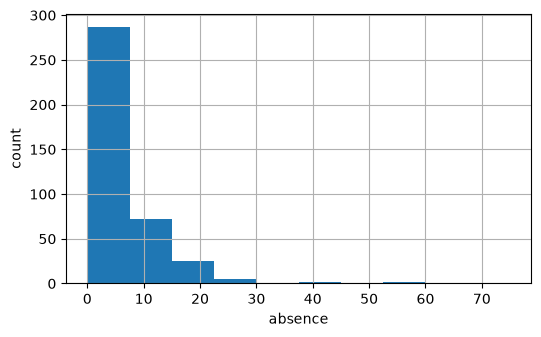

In [36]:
plt.hist(student_data['absences'])

plt.xlabel('absence')
plt.ylabel('count')

plt.grid(True)
plt.show()

La mayoría de los alumnos tiene pocas ausencias y unos pocos tienen muchas. Se hace lo mismo con otra variable numérica, `age`, para un análisis exploratorio de datos.

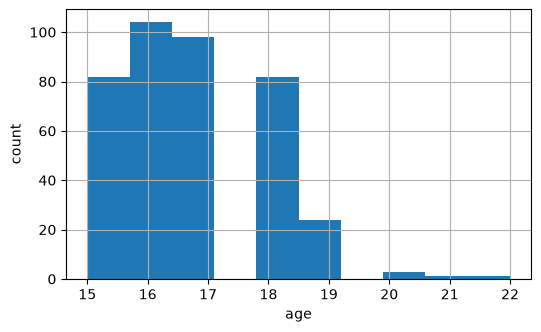

In [37]:
plt.hist(student_data['age'])

plt.xlabel('age')
plt.ylabel('count')

plt.grid(True)
plt.show()

**Ampliación (no está en el PDF):** el parámetro `bins` controla cuántos intervalos se usan y `sns.histplot()` es el equivalente de seaborn.

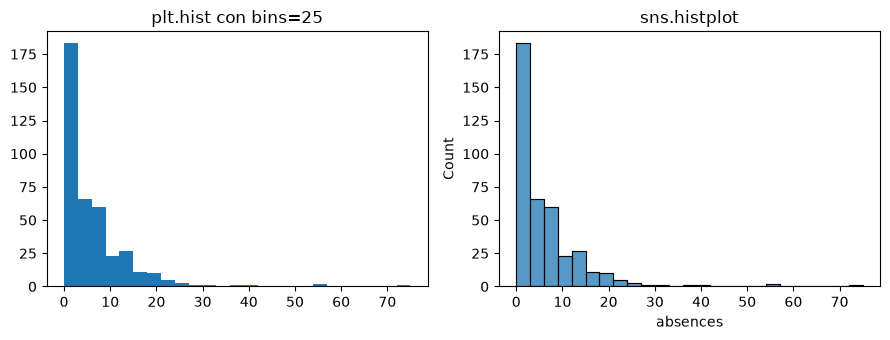

In [38]:
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.5))
ejes[0].hist(student_data['absences'], bins=25)
ejes[0].set_title("plt.hist con bins=25")
sns.histplot(student_data['absences'], bins=25, ax=ejes[1])
ejes[1].set_title("sns.histplot")
plt.tight_layout()
plt.show()

**Referencia:** PDF parte 1, págs. 48–49

### Paso 3: estadísticas descriptivas básicas

`describe()` resume las columnas numéricas con una sola llamada.

In [39]:
student_data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Mediana.** Es el valor central de los datos reordenados por tamaño. Aquí, la mediana del tiempo de estudio (`studytime`).

**Moda.** Es el valor más frecuente. `mode()` devuelve una Serie porque puede haber varios valores empatados.

In [40]:
print("Mediana de studytime:", student_data['studytime'].median())
print("Media de studytime:", round(student_data['studytime'].mean(), 4))
print("Moda de studytime:")
print(student_data['studytime'].mode())

Mediana de studytime: 2.0
Media de studytime: 2.0354
Moda de studytime:
0    2
Name: studytime, dtype: int64


**Varianza.** Indica si los datos están dispersos o concentrados alrededor de la media: se eleva al cuadrado la diferencia entre cada valor y la media, se suman y se divide. Se usan cuadrados porque la suma de las desviaciones sin elevar es cero. Cuanto menor es la varianza, menor es la dispersión.

In [41]:
varianza = student_data['studytime'].var()
print(varianza)

# Comprobación manual. Pandas divide por n-1 (ddof=1)
x = student_data['studytime']
manual = ((x - x.mean()) ** 2).sum() / (len(x) - 1)
print(manual)

0.7043243590567373
0.7043243590567373


**Nota sobre el PDF:** la diapositiva explica la varianza como "dividido por el número total"; pandas, en cambio, divide por `n - 1` (corrección de Bessel, `ddof=1`). NumPy (`np.var`) divide por `n` por defecto. Para muestras se usa `n - 1`.

**Desviación típica (estándar).** Es la raíz cuadrada de la varianza, y por eso tiene la misma unidad que los datos. Cuanto más cerca de 0, más concentrados están los datos alrededor de la media; cuanto mayor, más dispersos.

**Nota sobre el PDF:** el texto dice que la desviación típica es "uno de los gráficos de dispersión": se refiere a una *medida* de dispersión, no a un gráfico.

In [42]:
print(student_data['studytime'].std())
print(np.sqrt(student_data['studytime'].var()))   # es la raíz de la varianza

0.8392403464185556
0.8392403464185556


**Referencia:** PDF parte 1, págs. 50–53

**Visualización mediante diagrama de caja (box plot).** Conceptos necesarios, según el PDF:

| Concepto | Significado |
|---|---|
| Percentil | datos divididos en cien partes iguales |
| Cuartil | datos divididos en cuatro partes |
| Mediana (Q2) | el valor en la mitad de los datos |
| Tercer cuartil (Q3) | valor que deja por debajo el 75 % de los datos (el 25 % superior está por encima) |
| Primer cuartil (Q1) | valor que deja por debajo el 25 % de los datos |
| Intervalo intercuartílico (IQR) | la caja: de Q1 a Q3, el 50 % central de los datos |

**Nota sobre el PDF:** la tabla del PDF describe Q1 como "el valor correspondiente al 25 % inferior, es decir, el 75 % de los datos totales", lo que es confuso. Q1 es el valor por debajo del cual está el 25 % de los datos, y Q3 el valor por debajo del cual está el 75 %.

El diagrama muestra la caja (de Q1 a Q3), una línea en la mediana (Q2) y **bigotes** que se extienden hacia el mínimo y el máximo. Los puntos fuera de los bigotes son datos atípicos.

Q1=8.0  Q2 (mediana)=11.0  Q3=13.0  IQR=5.0


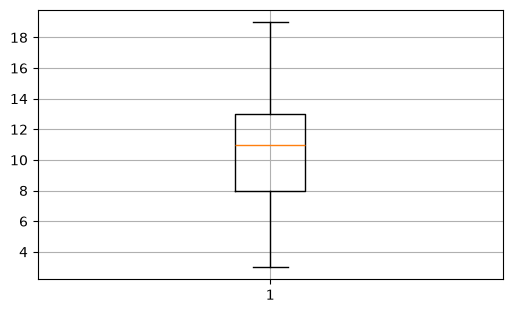

In [43]:
g1 = student_data['G1']
q1, q2, q3 = g1.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  Q2 (mediana)={q2}  Q3={q3}  IQR={q3 - q1}")

plt.boxplot(student_data['G1'])    # G1: calificaciones del primer período
plt.grid(True)
plt.show()

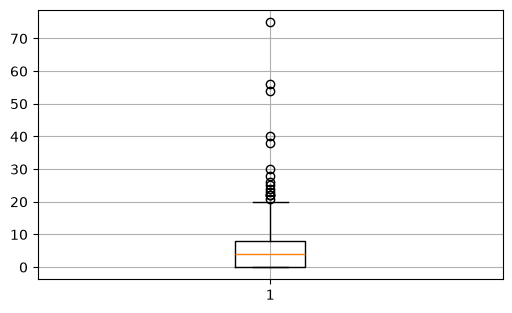

In [44]:
plt.boxplot(student_data['absences'])    # número de días de ausencia
plt.grid(True)
plt.show()

En el diagrama de las ausencias hay muchos datos anormales (los círculos sobre el bigote superior). Se pueden comparar varias variables a la vez pasando una lista.

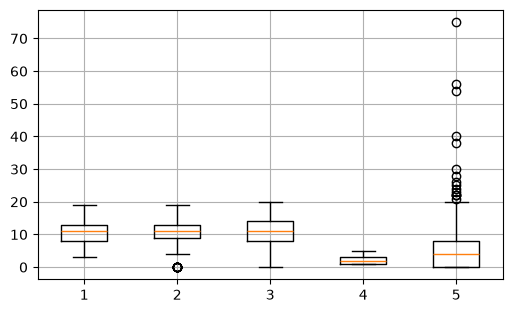

In [45]:
plt.boxplot([student_data['G1'], student_data['G2'], student_data['G3'],
             student_data['Walc'], student_data['absences']])
plt.grid(True)
plt.show()

Las cajas 1, 2 y 3 son las calificaciones G1, G2 y G3, la 4 es el consumo de alcohol de fin de semana (`Walc`) y la 5 son las ausencias. Se puede obtener información sobre el rendimiento de los alumnos al compararlas. El eje horizontal solo muestra números porque no se asignaron nombres.

**Ampliación (no está en el PDF):** los bigotes de matplotlib llegan hasta el dato más lejano dentro de `1,5 * IQR` desde la caja; lo que queda fuera se dibuja como punto. Se puede contar cuántas ausencias son atípicas y usar `sns.boxplot` para etiquetar las cajas.

Límite superior de bigote: 20.0; atípicos: 15 de 395


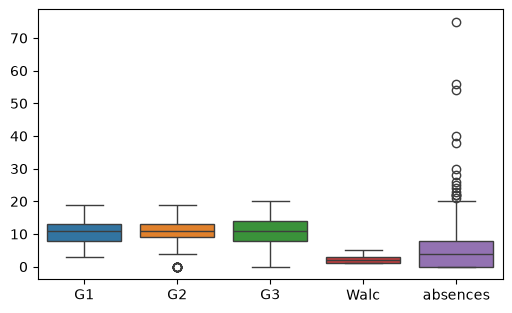

In [46]:
a = student_data['absences']
qa1, qa3 = a.quantile([0.25, 0.75])
iqr = qa3 - qa1
limite = qa3 + 1.5 * iqr
print(f"Límite superior de bigote: {limite}; atípicos: {(a > limite).sum()} de {len(a)}")

sns.boxplot(data=student_data[['G1', 'G2', 'G3', 'Walc', 'absences']])
plt.show()

**Referencia:** PDF parte 1, págs. 54–58

### Paso 4: coeficiente de variación, covarianza y correlación

**Coeficiente de variación (CV).** Variables con distinta unidad o magnitud no se pueden comparar por su desviación, porque la desviación crece cuando la escala es grande. El CV divide la desviación típica por la media, así que sirve para comparar datos de distinta escala:

`CV = desviación típica / media`

In [47]:
try:
    cv = student_data.std() / student_data.mean()      # forma del PDF
except TypeError as error:
    print("Error con columnas de texto:", error)

Error con columnas de texto: Cannot perform reduction 'std' with string dtype


**Nota sobre el PDF:** el PDF muestra el resultado con un `FutureWarning` sobre "nuisance columns" (pandas 1.x): en esa versión se ignoraban las columnas no numéricas. En pandas 3 el mismo código lanza `TypeError`, porque `school`, `sex` y otras columnas son texto. Hay que pedir explícitamente solo las columnas numéricas con `numeric_only=True`, que es lo que recomienda el propio aviso del PDF.

In [48]:
cv = student_data.std(numeric_only=True) / student_data.mean(numeric_only=True)
cv.round(6)

age           0.076427
Medu          0.398177
Fedu          0.431565
traveltime    0.481668
studytime     0.412313
failures      2.225319
famrel        0.227330
freetime      0.308725
goout         0.358098
Dalc          0.601441
Walc          0.562121
health        0.391147
absences      1.401873
G1            0.304266
G2            0.351086
G3            0.439881
dtype: float64

`failures` (2,22) y `absences` (1,40) tienen la mayor variabilidad relativa; `age` (0,076) es la variable más homogénea.

**Covarianza.** Representa la relación entre dos variables: se multiplican las desviaciones de ambas respecto a sus medias y se promedian. Un valor positivo indica que las variables tienden a moverse en el mismo sentido; uno negativo, en sentidos opuestos. Se calcula con `cov()`.

**Nota sobre el PDF:** "si la covarianza es positiva, las dos variables son positivas" significa que ambas suben o bajan juntas, no que sus valores sean positivos.

In [49]:
student_data.cov(numeric_only=True).round(3).iloc[:6, :6]   # parte de la matriz de covarianza

,age,Medu,Fedu,traveltime,studytime,failures
age,1.628,-0.229,-0.227,0.063,-0.004,0.231
Medu,-0.229,1.198,0.743,-0.131,0.060,-0.193
Fedu,-0.227,0.743,1.184,-0.120,-0.008,-0.203
traveltime,0.063,-0.131,-0.120,0.487,-0.059,0.048
studytime,-0.004,0.060,-0.008,-0.059,0.704,-0.108
failures,0.231,-0.193,-0.203,0.048,-0.108,0.553


`DataFrame.cov()` devuelve la covarianza de cada par de columnas. NumPy también calcula la covarianza con `np.cov()`: para dos series devuelve una matriz 2x2.

In [50]:
matriz = np.cov(student_data['G1'], student_data['G3'])
print(matriz)

[[11.01705327 12.18768232]
 [12.18768232 20.9896164 ]]


Análisis de la matriz, según el PDF:

- Covarianza entre G1 y G3: elementos (1,2) y (2,1), 12,18768232.
- Varianza de G1: elemento (1,1), 11,01705327.
- Varianza de G3: elemento (2,2), 20,9896164.

La diagonal contiene las varianzas. Se puede comprobar con `var()`:

In [51]:
print(student_data['G1'].var())
print(student_data['G3'].var())
verificar("la varianza de G1 coincide con el elemento (1,1)", round(student_data['G1'].var(), 6), round(matriz[0, 0], 6))
verificar("la varianza de G3 coincide con el elemento (2,2)", round(student_data['G3'].var(), 6), round(matriz[1, 1], 6))

11.017053267364904
20.989616397866733
Correcto: la varianza de G1 coincide con el elemento (1,1)
Correcto: la varianza de G3 coincide con el elemento (2,2)


**Coeficiente de correlación.** La covarianza depende de la escala y la unidad de cada variable, así que su tamaño no se puede interpretar. El coeficiente de correlación elimina esa dependencia: mide el grado en que dos variables se mueven juntas, siempre entre -1 y 1.

| Valor | Significado |
|---|---|
| 1,0 | correlación positiva completa: las dos se mueven en la misma dirección |
| 0,0 | las dos variables no tienen relación (lineal) |
| -1,0 | correlación negativa completa o inversa: se mueven en direcciones opuestas |

Se calcula con `corr()`.

**Nota sobre el PDF:** la diapositiva 65 tiene un signo de interrogación tras "se mueven"; es un fallo de traducción de "move together".

In [52]:
correlacion = student_data.corr(numeric_only=True)
correlacion.round(3).iloc[:6, :6]

,age,Medu,Fedu,traveltime,studytime,failures
age,1.000,-0.164,-0.163,0.071,-0.004,0.244
Medu,-0.164,1.000,0.623,-0.172,0.065,-0.237
Fedu,-0.163,0.623,1.000,-0.158,-0.009,-0.250
traveltime,0.071,-0.172,-0.158,1.000,-0.101,0.092
studytime,-0.004,0.065,-0.009,-0.101,1.000,-0.174
failures,0.244,-0.237,-0.250,0.092,-0.174,1.000


In [53]:
print(correlacion.loc[['G1', 'G2', 'G3'], ['G1', 'G2', 'G3']].round(3))

# Ampliación (no está en el PDF): correlación = covarianza / (std_x * std_y)
g1, g3 = student_data['G1'], student_data['G3']
print(round(g1.cov(g3) / (g1.std() * g3.std()), 6), "=", round(g1.corr(g3), 6))

       G1     G2     G3
G1  1.000  0.852  0.801
G2  0.852  1.000  0.905
G3  0.801  0.905  1.000
0.801468 = 0.801468


G1, G2 y G3 están muy correlacionadas entre sí. Las demás variables (por ejemplo `studytime` o `absences`) tienen una correlación débil con G3.

**Diagrama de dispersión.** Cada punto es un alumno: eje x = G1 (primera prueba), eje y = G3 (nota final). Muestra que quienes empiezan con buenas notas suelen terminar con buenos resultados.

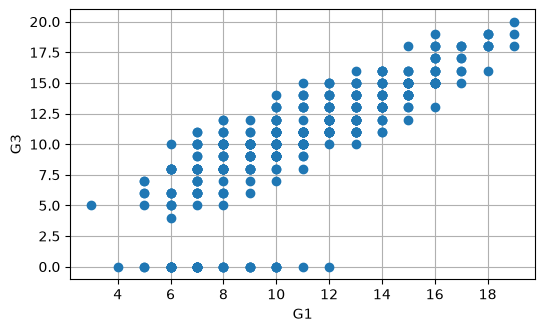

In [54]:
plt.plot(student_data['G1'], student_data['G3'], 'o')
plt.grid(True)
plt.xlabel('G1')
plt.ylabel('G3')
plt.show()

La fila de puntos con G3 = 0 corresponde a alumnos con calificación final nula, que quedan por debajo de la tendencia.

**Ampliación (no está en el PDF):** `plt.scatter()` y `sns.scatterplot()` son las funciones específicas de matplotlib y seaborn para este gráfico; `sns.heatmap()` muestra una matriz de correlación como mapa de color.

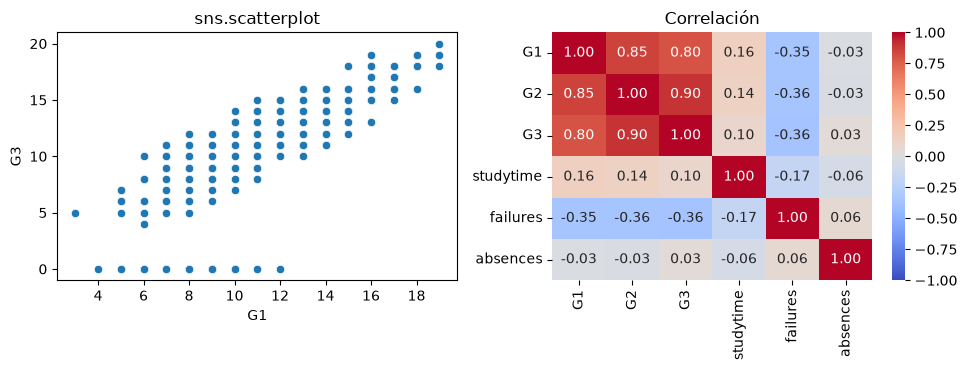

In [55]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.scatterplot(data=student_data, x='G1', y='G3', ax=ejes[0])
ejes[0].set_title("sns.scatterplot")
cols = ['G1', 'G2', 'G3', 'studytime', 'failures', 'absences']
sns.heatmap(student_data[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ejes[1])
ejes[1].set_title("Correlación")
plt.tight_layout()
plt.show()

**Referencia:** PDF parte 1, págs. 59–67

### Paso 5: histogramas y diagramas de dispersión de las variables elegidas

`sns.pairplot()` dibuja de una vez, para varias columnas, un histograma de cada variable (en la diagonal) y un diagrama de dispersión de cada par (fuera de la diagonal).

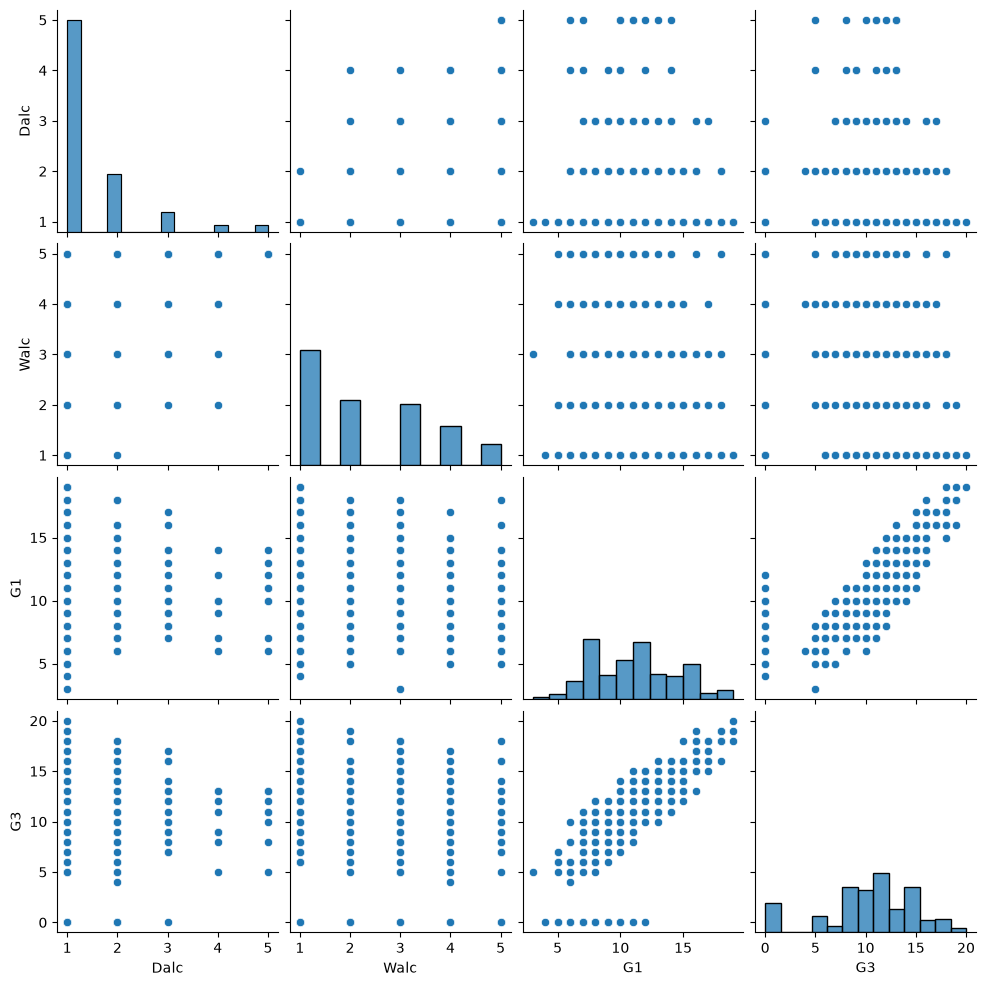

In [56]:
sns.pairplot(student_data[['Dalc', 'Walc', 'G1', 'G3']])
plt.grid(True)
plt.show()

**Nota sobre el PDF:** `plt.grid(True)` después de `pairplot` solo actúa sobre el último subgráfico, por eso no se ve cuadrícula en el resto.

Lectura rápida: `Dalc` y `Walc` (alcohol) se concentran en los valores bajos; G1 y G3 forman una nube ascendente, coherente con la correlación alta calculada antes.

**Referencia:** PDF parte 1, pág. 68

### Código final: todo el análisis en una función

La función junta los pasos de la misión: lee, comprueba NaN y calcula las estadísticas de una columna. Devuelve un diccionario para poder verificar el resultado.

In [57]:
def analizar_columna(ruta, columna, sep=";"):
    """Lee el CSV, comprueba si faltan datos y calcula las estadísticas descriptivas de una columna."""
    datos = pd.read_csv(ruta, sep=sep)                         # paso 1: crear el DataFrame
    total_nan = int(datos.isnull().sum().sum())                # paso 1: buscar NaN
    if total_nan > 0:                                          # preprocesamiento solo si hace falta
        datos = datos.dropna(subset=[columna])
    serie = datos[columna]
    return {                                                   # pasos 3 y 4
        "filas": len(datos),
        "nan": total_nan,
        "media": round(serie.mean(), 4),
        "mediana": float(serie.median()),
        "moda": serie.mode().tolist(),
        "varianza": round(serie.var(), 4),
        "desviacion": round(serie.std(), 4),
        "cv": round(serie.std() / serie.mean(), 4),
    }

resultado = analizar_columna(RUTA_ESTUDIANTES, "studytime")
for clave, valor in resultado.items():
    print(f"{clave:>10}: {valor}")

verificar("mediana de studytime", resultado["mediana"], 2.0)
verificar("moda de studytime", resultado["moda"], [2])
verificar("varianza de studytime", resultado["varianza"], 0.7043)
verificar("desviación de studytime", resultado["desviacion"], 0.8392)

     filas: 395
       nan: 0
     media: 2.0354
   mediana: 2.0
      moda: [2]
  varianza: 0.7043
desviacion: 0.8392
        cv: 0.4123
Correcto: mediana de studytime
Correcto: moda de studytime
Correcto: varianza de studytime
Correcto: desviación de studytime


**Resultado esperado (según el PDF):** 395 filas y 33 columnas sin ningún NaN; mediana de `studytime` 2,0; moda 2; varianza 0,7043; desviación típica 0,8392; covarianza de G1 y G3 12,1877 y varianzas 11,0171 y 20,9896.

### Programación en pareja

El PDF dedica las págs. 69–71 a recomendaciones sobre programación en pareja: preparar pautas y mecanismos (por ejemplo, turnarse el ratón), emparejar a personas con habilidades similares, ofrecer incentivos y evitar trampas con tareas significativas. La pág. 72 propone un ejercicio:

> **Q1.** Después de convertir el archivo `universities_ranking.csv` de la carpeta de prácticas en un DataFrame, comprueba si faltan datos y decide con tu compañero cómo sustituirlos o eliminarlos por completo. Los resultados del debate deben organizarse mediante códigos reales.

**Nota:** el archivo `universities_ranking.csv` no forma parte de este repositorio. El ejercicio 8 de la Práctica aplica la misma idea (comprobar y decidir qué hacer con los NaN) sobre una tabla pequeña creada aquí.

**Referencia:** PDF parte 1, págs. 69–72

## Práctica

Ocho ejercicios de dificultad creciente. Las celdas de verificación imprimen "Incorrecto" hasta que completes la función.

### Ejercicio 1 — Contar los datos que faltan

Escribe `contar_nan(df)`, que devuelva como `int` el número total de valores NaN de un DataFrame.

In [58]:
def contar_nan(df):
    # Escribe tu solución aquí
    pass

In [59]:
try:
    df1 = pd.DataFrame({"a": [1, np.nan, 3], "b": ["x", None, "y"]})
    df2 = pd.DataFrame({"a": [1, 2], "b": [3, 4]})
    df3 = pd.DataFrame({"a": [np.nan, np.nan], "b": [np.nan, np.nan]})
    verificar("dos NaN", contar_nan(df1), 2)
    verificar("ninguno", contar_nan(df2), 0)
    verificar("todos", contar_nan(df3), 4)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: dos NaN. Se esperaba 2 y se obtuvo None
Incorrecto: ninguno. Se esperaba 0 y se obtuvo None
Incorrecto: todos. Se esperaba 4 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def contar_nan(df):
    return int(df.isnull().sum().sum())
```

`isnull()` marca cada NaN con `True`; el primer `sum()` cuenta por columna y el segundo suma las columnas.
</details>

### Ejercicio 2 — Columnas con datos que faltan

Escribe `columnas_con_nan(df)`, que devuelva la lista con los nombres de las columnas que tienen al menos un NaN.

In [60]:
def columnas_con_nan(df):
    # Escribe tu solución aquí
    pass

In [61]:
try:
    df1 = pd.DataFrame({"a": [1, np.nan, 3], "b": [1, 2, 3], "c": ["x", None, "y"]})
    verificar("a y c", columnas_con_nan(df1), ["a", "c"])
    verificar("ninguna", columnas_con_nan(pd.DataFrame({"z": [1, 2]})), [])
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: a y c. Se esperaba ['a', 'c'] y se obtuvo None
Incorrecto: ninguna. Se esperaba [] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def columnas_con_nan(df):
    return [c for c in df.columns if df[c].isnull().any()]
```

`isnull().any()` es `True` si la columna tiene al menos un NaN; la lista por comprensión conserva el orden de las columnas.
</details>

### Ejercicio 3 — Eliminar las filas sin dato en una columna

Escribe `eliminar_filas_sin(df, columna)`, que devuelva un DataFrame sin las filas donde `columna` es NaN (usa `dropna` con `subset`).

In [62]:
def eliminar_filas_sin(df, columna):
    # Escribe tu solución aquí
    pass

In [63]:
try:
    df1 = pd.DataFrame({"edad": [20, np.nan, 30, np.nan], "nota": [1, 2, np.nan, 4]})
    res = eliminar_filas_sin(df1, "edad")
    verificar("quedan 2 filas", len(res), 2)
    verificar("índices conservados", res.index.tolist(), [0, 2])
    verificar("el original no cambia", len(df1), 4)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: la solución aún no está completa (TypeError)


<details><summary>Ver solución</summary>

```python
def eliminar_filas_sin(df, columna):
    return df.dropna(subset=[columna])
```

`subset=[columna]` limita la búsqueda de NaN a esa columna; el NaN de `nota` en la fila 2 no la elimina. `dropna` devuelve un DataFrame nuevo.
</details>

### Ejercicio 4 — Rellenar con la media

Escribe `rellenar_con_media(df, columna)`, que devuelva una copia del DataFrame con los NaN de `columna` sustituidos por su media. No modifiques el DataFrame original.

In [64]:
def rellenar_con_media(df, columna):
    # Escribe tu solución aquí
    pass

In [65]:
try:
    df1 = pd.DataFrame({"x": [2.0, np.nan, 4.0]})
    res = rellenar_con_media(df1, "x")
    verificar("valores rellenados", res["x"].tolist(), [2.0, 3.0, 4.0])
    verificar("el original conserva su NaN", int(df1["x"].isnull().sum()), 1)
    verificar("la copia no tiene NaN", int(res["x"].isnull().sum()), 0)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: la solución aún no está completa (TypeError)


<details><summary>Ver solución</summary>

```python
def rellenar_con_media(df, columna):
    nuevo = df.copy()
    nuevo[columna] = nuevo[columna].fillna(nuevo[columna].mean())
    return nuevo
```

La media ignora los NaN (2 y 4 dan 3). Se asigna el resultado de `fillna` a la columna de la copia, en lugar de usar `inplace=True` sobre `df[columna]`.
</details>

### Ejercicio 5 — Rellenar con la moda

Escribe `rellenar_con_moda(df, columna)`, que devuelva una copia con los NaN de `columna` sustituidos por su valor más frecuente.

In [66]:
def rellenar_con_moda(df, columna):
    # Escribe tu solución aquí
    pass

In [67]:
try:
    df1 = pd.DataFrame({"ciudad": ["Panamá", "Colón", "Panamá", None]})
    res = rellenar_con_moda(df1, "ciudad")
    verificar("rellena con la moda", res["ciudad"].tolist(), ["Panamá", "Colón", "Panamá", "Panamá"])
    verificar("el original conserva su NaN", int(df1["ciudad"].isnull().sum()), 1)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: la solución aún no está completa (TypeError)


<details><summary>Ver solución</summary>

```python
def rellenar_con_moda(df, columna):
    nuevo = df.copy()
    nuevo[columna] = nuevo[columna].fillna(nuevo[columna].mode()[0])
    return nuevo
```

`mode()` devuelve una Serie (puede haber empates) y `[0]` toma la primera moda; los NaN no cuentan como valor.
</details>

### Ejercicio 6 — Coeficiente de variación

Escribe `coeficiente_variacion(serie)`, que devuelva desviación típica dividida por la media, redondeada a 4 decimales.

In [68]:
def coeficiente_variacion(serie):
    # Escribe tu solución aquí
    pass

In [69]:
try:
    verificar("10, 20, 30", coeficiente_variacion(pd.Series([10, 20, 30])), 0.5)
    verificar("sin dispersión", coeficiente_variacion(pd.Series([5, 5, 5])), 0.0)
    verificar("1, 2, 3", coeficiente_variacion(pd.Series([1, 2, 3])), 0.5)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: 10, 20, 30. Se esperaba 0.5 y se obtuvo None
Incorrecto: sin dispersión. Se esperaba 0.0 y se obtuvo None
Incorrecto: 1, 2, 3. Se esperaba 0.5 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def coeficiente_variacion(serie):
    return round(serie.std() / serie.mean(), 4)
```

En [10, 20, 30] la desviación es 10 y la media 20, por lo que el CV es 0,5. `std()` de pandas divide por n-1.
</details>

### Ejercicio 7 — Valores atípicos con la regla del diagrama de caja

Escribe `valores_atipicos(serie)`, que devuelva la lista de los valores que están fuera del intervalo `[Q1 - 1,5*IQR, Q3 + 1,5*IQR]` (los puntos que dibuja un box plot).

In [70]:
def valores_atipicos(serie):
    # Escribe tu solución aquí
    pass

In [71]:
try:
    verificar("un atípico", valores_atipicos(pd.Series([1, 2, 3, 4, 5, 6, 7, 8, 9, 100])), [100])
    verificar("sin atípicos", valores_atipicos(pd.Series([1, 2, 3, 4, 5, 6, 7, 8, 9])), [])
    verificar("atípico bajo", valores_atipicos(pd.Series([-50, 10, 11, 12, 13, 14, 15, 16])), [-50])
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: un atípico. Se esperaba [100] y se obtuvo None
Incorrecto: sin atípicos. Se esperaba [] y se obtuvo None
Incorrecto: atípico bajo. Se esperaba [-50] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def valores_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return serie[(serie < bajo) | (serie > alto)].tolist()
```

Para [1..9, 100]: Q1 = 3,25, Q3 = 7,75 e IQR = 4,5, por lo que el límite superior es 14,5 y solo 100 lo supera.
</details>

### Ejercicio 8 — Limpieza completa (ejercicio de pareja)

Es el equivalente del ejercicio Q1 de la programación en pareja. Escribe `limpiar(df, umbral=0.5)`: elimina las columnas cuya proporción de NaN sea mayor que `umbral`; en las que queden, rellena los NaN numéricos con la mediana y los demás con la moda. Devuelve un DataFrame nuevo.

In [72]:
def limpiar(df, umbral=0.5):
    # Escribe tu solución aquí
    pass

In [73]:
try:
    tabla = pd.DataFrame({
        "puntaje": [1.0, np.nan, 3.0, 5.0],
        "premio": [np.nan, np.nan, np.nan, "oro"],
        "pais": ["Chile", "Perú", "Chile", None],
    })
    res = limpiar(tabla)
    verificar("se elimina la columna con 75 % de NaN", res.columns.tolist(), ["puntaje", "pais"])
    verificar("mediana en la columna numérica", res["puntaje"].tolist(), [1.0, 3.0, 3.0, 5.0])
    verificar("moda en la columna de texto", res["pais"].tolist(), ["Chile", "Perú", "Chile", "Chile"])
    verificar("sin NaN al final", int(res.isnull().sum().sum()), 0)
except Exception as error:
    print(f"Incorrecto: la solución aún no está completa ({type(error).__name__})")

Incorrecto: la solución aún no está completa (AttributeError)


<details><summary>Ver solución</summary>

```python
def limpiar(df, umbral=0.5):
    nuevo = df.loc[:, df.isnull().mean() <= umbral].copy()
    for col in nuevo.columns:
        if nuevo[col].isnull().any():
            if pd.api.types.is_numeric_dtype(nuevo[col]):
                nuevo[col] = nuevo[col].fillna(nuevo[col].median())
            else:
                nuevo[col] = nuevo[col].fillna(nuevo[col].mode()[0])
    return nuevo
```

`df.isnull().mean()` da la proporción de NaN por columna y sirve de máscara de columnas. Después se decide por tipo: mediana para numéricos y moda para categóricos.
</details>

## Apuntes para estudiar

**Clave**

- Datos ordenados (Tidy Data): una variable por columna, una observación por fila y un valor por celda.
- Un dato que falta aparece como `NaN`. Se detecta con `isnull()`/`isna()` (y `notnull()`/`notna()` es lo contrario); `df.isnull().sum()` cuenta por columna y un segundo `.sum()` da el total.
- `info()` muestra los no nulos por columna; `value_counts(dropna=False)` incluye los NaN en el conteo.
- `dropna(axis=1, thresh=n)` elimina columnas con menos de `n` valores válidos; `dropna(subset=[col])` elimina filas sin dato en `col`; `how='all'` solo si toda la fila o columna es NaN.
- `fillna()` sustituye: media/mediana para numéricos, moda (`value_counts().idxmax()` o `mode()[0]`) para categóricos, `ffill()`/`bfill()` para copiar el vecino.
- Estadísticas descriptivas: `mean()`, `median()`, `mode()`, `var()`, `std()`, `describe()`. La desviación típica es la raíz de la varianza y tiene la unidad de los datos.
- CV = desviación típica / media (compara escalas distintas). Covarianza (`cov()`) da el sentido de la relación; la correlación (`corr()`) está entre -1 y 1.
- Gráficos: `plt.hist()` (distribución), `plt.boxplot()` (mediana, cuartiles, atípicos), `plt.plot(x, y, 'o')` o `sns.scatterplot` (relación entre dos variables), `sns.pairplot()` (todo a la vez).

**Errores comunes**

- Comparar con `== np.nan` para buscar NaN: siempre da falso. Usar `isnull()`.
- Llamar a `dropna()` o `fillna()` sin guardar el resultado.
- `df['col'].fillna(valor, inplace=True)`: en pandas actual modifica una copia y el DataFrame no cambia; asignar `df['col'] = df['col'].fillna(valor)`.
- Usar `fillna(method='ffill')`: el parámetro `method` ya no existe; usar `ffill()` / `bfill()`.
- Pensar que `thresh` es el máximo de NaN permitidos; es el mínimo de valores no nulos.
- Leer un CSV separado por `;` sin `sep=";"`: queda todo en una columna.
- Calcular `std()`/`mean()` de un DataFrame con columnas de texto sin `numeric_only=True`.
- Interpretar la covarianza por su tamaño: depende de la escala; para eso está la correlación.

**Para el quiz**

- Las tres reglas de Tidy Data y el autor del término (Hadley Wickham).
- NaN significa *Not a Number*; `isnull().sum()` cuenta NaN por columna.
- Titanic: 891 filas; `age` tiene 177 NaN, `deck` 688, `embarked` 2 y `embark_town` 2; total 869.
- Con `thresh=500` se elimina `deck`; `dropna(subset=['age'])` deja 714 filas.
- Media de `age` = 29,699; `embark_town` más frecuente = Southampton.
- `student-mat.csv`: 395 filas y 33 columnas, separador `;`, sin NaN; mediana de `studytime` 2,0, moda 2, varianza 0,7043, desviación 0,8392.
- Q1 = 25 %, mediana = Q2 = 50 %, Q3 = 75 %; IQR = Q3 - Q1.
- Correlación: 1 = relación positiva completa, 0 = ninguna, -1 = inversa completa.

## Autoevaluación

**Pregunta 1.** ¿Cuáles son las tres reglas de los datos ordenados?

<details><summary>Ver respuesta</summary>

Cada variable en su propia columna, cada observación en su propia fila y cada valor en su propia celda.
</details>

**Pregunta 2.** En el Titanic, `age` tiene 714 valores no nulos y el DataFrame tiene 891 filas. ¿Cuántos NaN hay y qué dos formas conoces de comprobarlo?

<details><summary>Ver respuesta</summary>

Hay `891 - 714 = 177` NaN. Se comprueban con `df['age'].isnull().sum()` (o `len(df) - df.count()`), o con `df['age'].value_counts(dropna=False)`, que muestra los NaN como categoría.
</details>

**Pregunta 3.** ¿Cuándo conviene eliminar una columna con `dropna` y cuándo sustituir sus NaN?

<details><summary>Ver respuesta</summary>

Si la proporción de NaN es muy alta (como `deck`, con 688 de 891), la columna aporta poco y se elimina con `dropna(axis=1, thresh=...)`. Si faltan pocos datos y la variable es importante, se sustituyen con media o mediana (numéricos), moda (categóricos) o el valor vecino (`ffill`/`bfill`) para no perder filas.
</details>

**Pregunta 4.** ¿Qué diferencia hay entre varianza y desviación típica, y cómo se relacionan con el coeficiente de variación?

<details><summary>Ver respuesta</summary>

La varianza es el promedio de las diferencias cuadráticas respecto a la media (unidad al cuadrado); la desviación típica es su raíz cuadrada y tiene la misma unidad que los datos. El coeficiente de variación divide la desviación típica por la media, así permite comparar la dispersión de variables con escalas distintas.
</details>

**Pregunta 5.** Si `df['G1'].corr(df['G3'])` da un valor cercano a 0,8, ¿qué se concluye? ¿Y si diera -1?

<details><summary>Ver respuesta</summary>

Que G1 y G3 tienen una relación positiva fuerte: quienes tienen buena nota en G1 suelen tenerla en G3 (no prueba causalidad). Un valor de -1 sería correlación negativa completa: cuando una sube, la otra baja en proporción exacta.
</details>

---

[Índice de la semana](../semana-06.ipynb) | [Anterior](../semana-06.ipynb) | [Siguiente](u38-series-temporales.ipynb)